# 02. Huấn Luyện & Tối Ưu Mô Hình 1: Hồi Quy Logistic (Logistic Regression)

**Thành viên phụ trách:** Thành viên 2 - Linear Modeling & Mathematical Optimization

### Mục tiêu & Nhiệm vụ của Thành viên 2:
1. **Mô hình hóa tuyến tính:** Xây dựng mô hình phân loại nhị phân cổ điển dựa trên hàm kích hoạt Sigmoid và hàm mất mát Binary Cross-Entropy có phạt mất cân bằng lớp (`class_weight='balanced'`).
2. **Kiểm chuẩn mô hình:** Huấn luyện song song mô hình cơ sở ngẫu nhiên `DummyClassifier(strategy='prior')` để làm thước đo tham chiếu bắt buộc.
3. **Phân tích khả năng giải thích (Explainability):** Trích xuất vector trọng số hệ số $\mathbf{w} \in \mathbb{R}^{24}$ và tỷ số chênh Odds Ratio ($e^{w_j}$) để phân tích định lượng tầm ảnh hưởng của từng chỉ số lên xác suất được bầu chọn All-Star.
4. **Đánh giá hiệu năng:** Đo lường Precision, Recall, F1, PR-AUC, ROC-AUC trên tập Validation ($2017 - 2019$) và Test ($2020 - 2026$).
5. **Đóng gói sản phẩm:** Lưu trữ mô hình vào `models/LogisticRegression.joblib` và cập nhật dự đoán vào `reports/predictions.csv`.

In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().resolve().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình font hiển thị
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font="Segoe UI")

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score
import joblib

print("Đã import thành công các thư viện cần thiết cho Thành viên 2!")

Đã import thành công các thư viện cần thiết cho Thành viên 2!


## Bước 1: Nạp Dữ Liệu Train, Validation, Test & Khai Báo 24 Đặc Trưng
Dữ liệu đã được Thành viên 1 làm sạch và chia theo thời gian nhân quả: tập Train (mùa $\le 2016$), Validation ($2017 - 2019$), Test ($2020 - 2026$).

In [2]:
processed_dir = ROOT_DIR / "data" / "processed"

train_df = pd.read_csv(processed_dir / "train.csv")
val_df = pd.read_csv(processed_dir / "val.csv")
test_df = pd.read_csv(processed_dir / "test.csv")

feature_cols = [
    'pts_per_game_zscore', 'ast_per_game_zscore', 'trb_per_game_zscore',
    'per_zscore', 'ws_zscore', 'vorp_zscore',
    'team_win_pct', 'prev_allstar_count',
    'mp_per_game', 'pts_per_game', 'ast_per_game', 'trb_per_game',
    'stl_per_game', 'blk_per_game', 'tov_per_game',
    'fg_percent', 'x3p_percent', 'ft_percent',
    'per', 'ts_percent', 'usg_percent', 'ws', 'bpm', 'vorp'
]
feature_cols = [c for c in feature_cols if c in train_df.columns]
target_col = "All_Star"

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Tập Train (<= 2016):      {X_train.shape[0]:,} dòng | Tỷ lệ All-Star: {y_train.mean():.2%}")
print(f"Tập Validation (2017-19):  {X_val.shape[0]:,} dòng | Tỷ lệ All-Star: {y_val.mean():.2%}")
print(f"Tập Test (2020-2026):     {X_test.shape[0]:,} dòng | Tỷ lệ All-Star: {y_test.mean():.2%}")
print(f"Số lượng đặc trưng sử dụng: {len(feature_cols)}")

Tập Train (<= 2016):      11,473 dòng | Tỷ lệ All-Star: 7.95%
Tập Validation (2017-19):  1,187 dòng | Tỷ lệ All-Star: 6.74%
Tập Test (2020-2026):     2,882 dòng | Tỷ lệ All-Star: 6.45%
Số lượng đặc trưng sử dụng: 24


## Bước 2: Khởi Tạo & Huấn Luyện Mô Hình 1 (Logistic Regression)

Hàm xác suất dự đoán của mô hình Hồi quy Logistic:
$$P(y_i = 1 \mid \mathbf{x}_i) = \sigma(\mathbf{w}^T \mathbf{x}_i + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x}_i + b)}}$$

Do tỷ lệ All-Star chỉ chiếm $\approx 7.5\%$, chúng ta áp dụng trọng số cân bằng lớp:
$$w_1 = \frac{N}{2 \cdot N_1} \approx 6.67, \quad w_0 = \frac{N}{2 \cdot N_0} \approx 0.54$$
giúp mô hình phạt nặng gấp $12.3$ lần khi bỏ sót một cầu thủ All-Star!

In [3]:
# Khởi tạo mô hình kiểm chuẩn Dummy và mô hình chính LogisticRegression
dummy = DummyClassifier(strategy="prior")
logreg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42, solver="lbfgs")

print("Đang huấn luyện Dummy và LogisticRegression...")
dummy.fit(X_train, y_train)
logreg.fit(X_train, y_train)
print("Huấn luyện thành công!")

Đang huấn luyện Dummy và LogisticRegression...


Huấn luyện thành công!


c:\Users\Administrator\.gemini\antigravity\scratch\nba-allstar-prediction\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Bước 3: Phân Tích Hệ Số Trọng Số $\mathbf{w}$ (Coefficients & Odds Ratio)
Trích xuất và vẽ đồ thị các trọng số $\beta_j$ đại diện cho mức độ gia tăng tỷ số chênh Odds Ratio của từng chỉ số.

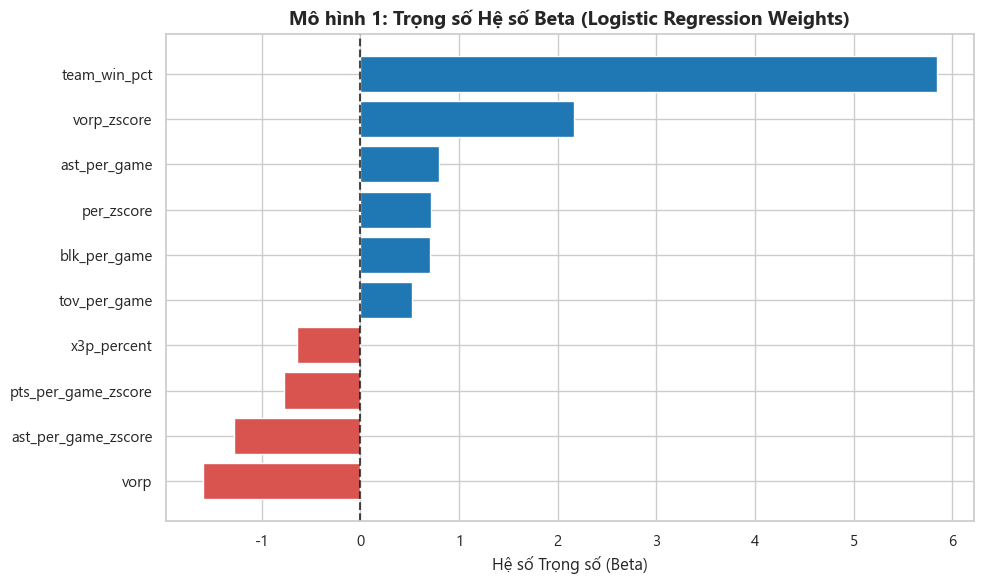

Top 5 đặc trưng thúc đẩy xác suất All-Star mạnh nhất:


,feature,weight,odds_ratio
0,team_win_pct,5.845912,345.817838
1,vorp_zscore,2.167537,8.736736
2,ast_per_game,0.792020,2.207852
3,per_zscore,0.719582,2.053575
4,blk_per_game,0.708055,2.030039


In [4]:
coef_df = pd.DataFrame({
    "feature": feature_cols,
    "weight": logreg.coef_[0],
    "odds_ratio": np.exp(logreg.coef_[0])
}).sort_values("weight", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
top_coefs = pd.concat([coef_df.head(6), coef_df.tail(4)]).sort_values("weight")
colors = ['#d9534f' if w < 0 else '#1f77b4' for w in top_coefs["weight"]]
plt.barh(top_coefs["feature"], top_coefs["weight"], color=colors)
plt.title("Mô hình 1: Trọng số Hệ số Beta (Logistic Regression Weights)", fontsize=14, fontweight="bold")
plt.xlabel("Hệ số Trọng số (Beta)")
plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("Top 5 đặc trưng thúc đẩy xác suất All-Star mạnh nhất:")
coef_df.head(5)

## Bước 4: Đánh Giá Hiệu Năng Chi Tiết (Validation & Test Sets)
So sánh kết quả của Mô hình 1 với Dummy Baseline.

In [5]:
for split_name, X_eval, y_eval in [("Validation (2017-2019)", X_val, y_val), ("Test (2020-2026)", X_test, y_test)]:
    y_prob = logreg.predict_proba(X_eval)[:, 1]
    y_pred = logreg.predict(X_eval)
    
    prec = precision_score(y_eval, y_pred, zero_division=0)
    rec = recall_score(y_eval, y_pred, zero_division=0)
    f1 = f1_score(y_eval, y_pred, zero_division=0)
    pr = average_precision_score(y_eval, y_prob)
    roc = roc_auc_score(y_eval, y_prob)
    
    print(f"=== HIỆU NĂNG LOGISTIC REGRESSION TRÊN {split_name.upper()} ===")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f} (Bắt trúng {int(rec*y_eval.sum())}/{y_eval.sum()} cầu thủ)")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  PR-AUC:    {pr:.4f}")
    print(f"  ROC-AUC:   {roc:.4f}\n")

=== HIỆU NĂNG LOGISTIC REGRESSION TRÊN VALIDATION (2017-2019) ===
  Precision: 0.5746
  Recall:    0.9625 (Bắt trúng 77/80 cầu thủ)
  F1-Score:  0.7196
  PR-AUC:    0.8654
  ROC-AUC:   0.9858

=== HIỆU NĂNG LOGISTIC REGRESSION TRÊN TEST (2020-2026) ===
  Precision: 0.4866
  Recall:    0.9785 (Bắt trúng 182/186 cầu thủ)
  F1-Score:  0.6500
  PR-AUC:    0.8713
  ROC-AUC:   0.9900



## Bước 5: Lưu Trữ Mô Hình & Cập Nhật Dự Đoán
Xuất `LogisticRegression.joblib` vào `models/` và ghi kết quả vào `reports/predictions.csv`.

In [6]:
from src.train_logistic import update_predictions_file

models_dir = ROOT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(logreg, models_dir / "LogisticRegression.joblib")
joblib.dump(dummy, models_dir / "Dummy.joblib")
print(f"Đã lưu mô hình: LogisticRegression.joblib")

# Xuất dự đoán chuẩn 6 cột
def export_split_preds(df_split, X_split, y_split, split_label, model_label, model_obj):
    proba = model_obj.predict_proba(X_split)[:, 1] if hasattr(model_obj, 'predict_proba') else np.zeros(len(df_split))
    return pd.DataFrame({
        "player": df_split["player"].values,
        "season": df_split["season"].values,
        "split": split_label,
        "model": model_label,
        "y_true": y_split.values,
        "y_proba": proba
    })

preds_to_save = pd.concat([
    export_split_preds(val_df, X_val, y_val, "val", "LogisticRegression", logreg),
    export_split_preds(test_df, X_test, y_test, "test", "LogisticRegression", logreg),
    export_split_preds(val_df, X_val, y_val, "val", "Dummy", dummy),
    export_split_preds(test_df, X_test, y_test, "test", "Dummy", dummy),
], ignore_index=True)

pred_path = ROOT_DIR / "reports" / "predictions.csv"
updated_preds = update_predictions_file(preds_to_save, pred_path)
print(f"Đã cập nhật kết quả dự đoán ({len(updated_preds)} dòng) vào: {pred_path}")

Đã lưu mô hình: LogisticRegression.joblib
Đã cập nhật kết quả dự đoán (12207 dòng) vào: C:\Users\Administrator\.gemini\antigravity\scratch\nba-allstar-prediction\reports\predictions.csv
